# Case Study 15 — From a Wallet-Behaviour Score to BNPL Credit Limits: Score Building, a Randomised Limit Test, and Profit-Optimal Limits

**Priority:** ★★ Good to have · **Reference:** Case Study 15 — *MobiKwik: setting BNPL credit limits with a wallet-behaviour score (MobiScore)* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Credit (BNPL), Product (ZIP), Collections, Finance
**Data:** ⚠️ **SYNTHETIC** (D-15-01). Wallet and credit data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs15_bnpl_limit_assignment.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on MobiKwik's documented MobiScore design; MobiKwik disclosed no metrics. Written after the analysis.)*

- **The question:** who should get a BNPL line from wallet behaviour alone, and what limit maximises profit?
- **The behaviour score works.** Trained on one cohort and tested on another, it reaches **AUC 0.71** (KS 0.32). Bad rates rise steadily from **2.0% in the safest fifth to 15.6% in the riskiest**. The strongest signals are low-balance days, irregular last-minute top-ups and a low share of bills paid through the wallet.
- **Engagement signals are collections signals.** Being reachable barely changes default risk (odds ratio 0.88), but it **triples the odds of being cured** once a customer is 30+ days late (OR 2.99; cure 47% vs 23%). That is exactly why the documented score includes "contactability" and "responsiveness".
- **Past data gives the wrong answer about limits.** In the historical book, higher limits *look* safer (odds of default −11% per +₹1,000) because the old rule gave big limits to good customers. The **randomised limit test** shows the truth: each +₹1,000 of limit **raises default odds by 47%**, more for risky customers (+63% in the riskiest band, +16% in the safest; heterogeneity p ≈ 3e-18).
- **Profit by limit:**
  - **Large limits lose money for most customers:** ₹5,000 for everyone loses ₹145 per user in 6 months.
  - **Old-rule tiers are not optimal:** "score-tiered" limits (₹5k down to ₹1k) earn less than giving everyone ₹1,000.
  - **The profit-optimal policy** (₹5k for the safest fifth, ₹2k for the next, ₹1k for the rest) earns **₹30.1 per user vs ₹27.6 for uniform ₹1,000**. The gain is small and **not yet statistically certain** (+₹2.5, CI −₹1.4 to +₹6.1).
- **₹ impact (10 lakh pre-approved users per 6 months):**
  - The profit-optimal policy earns ≈ ₹3.0 crore, vs ₹2.3 crore under the old-rule tiers.
  - Uniform ₹5k would *lose* ≈ ₹14.5 crore.
  - The biggest money is in **avoiding high limits for risky users**, not in fine-tuning.
- **I recommend:**
  - Pre-approve on the behaviour score.
  - Start everyone at ₹1–2k and raise limits only for the safest band (₹5k), with a permanent 2–5% random-limit holdout to keep learning. The test needs ≈ 2,000–10,000 users per arm per band to detect a ₹20 profit difference.
  - Route contactability and responsiveness into the collections model, not the approval score.

## 1. The Problem in Simple English

MobiKwik knows how millions of wallet users behave: what they spend, whether they pay bills on time, whether they top up regularly or at the last minute, how often they change phones, and whether they respond when the app nudges them. Most have no bureau history. MobiKwik turns this into a **behaviour score (MobiScore)** and uses it for two decisions:
1. **Pre-approval:** who gets a BNPL ("ZIP") credit line at all.
2. **Limit:** how much (₹1,000? ₹5,000?).

The limit question is harder than it looks. A higher limit earns more (people spend more on it) but loses more when someone defaults. The *amount* lost depends on the limit, and so may the *chance* of default. Looking at past data misleads, because past limits were not random: good customers were given high limits, so high limits *look* safe.

This notebook:
- Builds the score.
- Shows why engagement signals (contactability, responsiveness) matter mostly for **collections**.
- Uses a **randomised limit test** to find the most profitable limit for each score band.

## 2. Reference from the Case File

### (a) What MobiKwik did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Pre-approve wallet users for BNPL ('ZIP') and set credit limits without a traditional bureau history" |
| Data | Behavioural ("spending patterns, payment patterns, outstanding amounts, channel preferences"); device/location ("device information, location history, app usage"); engagement ("contactability, responsiveness"); "**More than 500 raw and derived variables**" |
| Approach | Raw and derived variables feed **MobiScore**, which drives pre-approval and limits; ML collection strategies mentioned |
| Statistics / ML / metrics | **ND** |
| Decision | BNPL pre-approval and limit assignment by MobiScore; collections with 89 in-house staff (31 Mar 2021) plus agencies |
| Impact | **Not publicly disclosed** |

**Source:** Inc42, 13 Jul 2021 (summary of the DRHP filed 12 Jul 2021) — https://inc42.com/buzz/mobikwiks-mobiscore-collects-spending-patterns-device-information/

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | ≈ 132,000 pre-approved wallet users with 16 behavioural, device and engagement features, in two cohorts: **historical** (limits from the old rule, which favoured better-looking users) and **experiment** (limits randomly ₹1k / 2k / 3k / 5k). 6-month outcomes: line spend, revenue (2% merchant fee + late fees), 30+ DPD, 90+ DPD default, loss, and collections **cure** after 30+ DPD |
| Statistics added (none disclosed) | Feature screening (Mann–Whitney + rank-biserial, Holm); score AUC/KS with decile rank ordering; engagement features for default vs cure (odds ratios, LR tests); **confounding demonstration** (historical vs randomised limit effect); randomisation checks (SRM, SMD); limit × score-band heterogeneity (LR test); **profit-optimal limits** per band with bootstrap CIs, chosen on one half of the experiment and evaluated on the other; power |

### (c) How the industry uses this

Behaviour scores from first-party data drive limits at every Indian BNPL and credit-line product: Paytm Postpaid, Amazon Pay Later, Flipkart Pay Later, LazyPay, Simpl (Case 10) and MobiKwik ZIP. **Randomised credit-line tests** are standard at card issuers worldwide (Capital One's "test-and-learn"), because limit effects cannot be learned from historical data where limits followed risk. RBI's Digital Lending Guidelines (2022) require limits to be set by the regulated lender's credit policy, which is exactly this kind of documented, tested rule.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Who should get a BNPL line, and what limit maximises profit without excessive losses? |
| Analytical | (1) Does the behaviour score rank default risk? (2) What is the **causal** effect of a higher limit on spend, default and profit, and does it differ by score band? (3) Which limit per band maximises expected profit? |

**Hypotheses**
- **H1 (score):** H0: AUC of the score = 0.5 on the experiment cohort (out-of-cohort; DeLong CI).
- **H2 (engagement):** H0: contactability and responsiveness add no information to (a) default and (b) cure models (LR tests).
- **H3 (limit effect):** H0: default rate does not depend on the randomly assigned limit (χ² trend); H0b: the limit effect is the same in all score bands (LR test of limit × band).
- **H4 (policy):** H0: the score-based limit policy earns the same profit per user as the best uniform limit (paired bootstrap on the held-out half).

**Primary metric:** 6-month **profit per pre-approved user** = revenue − credit loss. **Guardrail:** portfolio default rate ≤ 6%. **Unit:** user.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public wallet-behaviour + credit-line outcome data | **None.** Wallet transaction data are confidential and personal (DPDP Act). No public dataset has randomised credit limits. |
| **Decision** | Synthetic users in two cohorts, one with randomised limits (D-15-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs15.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 15 (MobiKwik-style wallet-behaviour score for BNPL pre-approval and limits)
================================================================================================================
THIS DATA IS SYNTHETIC. Wallet and BNPL data are confidential.

Wallet users with 6 months of behaviour (spend patterns, bill payments, top-up habits, outstanding
amounts, channel preference, device/location stability, app usage) plus ENGAGEMENT signals
(contactability = verified reachable phone; responsiveness = reacts to in-app nudges).
Two cohorts receive BNPL ("ZIP") credit lines and are observed for 6 months:
  * HISTORICAL cohort - limits set by the old rule (better-looking users got higher limits): confounded
  * EXPERIMENT cohort - pre-approved users randomly assigned a limit of Rs 1k / 2k / 3k / 5k (credit-line test)
Outcomes: spend on the line, revenue (merchant fee + late fees), default (90+ DPD) and, for users who
become 30+ DPD, whether collections CURE them (where contactability/responsiveness matter most).
A higher limit raises spend for everyone but raises default mainly for low-quality users.

Calibration anchors (reference file, Case Study 15): "More than 500 raw and derived variables";
behavioural, device/location and engagement ("contactability, responsiveness") data feed MobiScore,
which drives pre-approval and limits. No metrics disclosed. Rates are our assumptions (decision.md
D-15-02). Hidden truth columns start with "_".

Output: data/cs15/users.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
LIMITS = [1000, 2000, 3000, 5000]


def generate(seed=SEED, n=140_000):
    rng = np.random.default_rng(seed)
    q = rng.normal(0, 1, n)                                                          # latent repayment quality
    need = rng.normal(0, 1, n)                                                       # latent credit appetite
    tenure_m = np.clip(rng.gamma(2.5, 9, n), 1, 96).round()
    txn_6m = rng.poisson(np.exp(3.2 + 0.25 * need + 0.15 * q))
    spend_6m = np.round(txn_6m * np.exp(rng.normal(np.log(420), 0.5, n) + 0.1 * need), -1)
    bill_pay_share = np.clip(rng.beta(2, 5, n) + 0.06 * q, 0, 1)                     # utilities / postpaid paid via wallet
    ontime_bill_rate = np.clip(rng.beta(8 + 2 * q.clip(-2, 2), 2, n), 0, 1)
    topup_regular = np.clip(rng.beta(3, 3, n) + 0.08 * q, 0, 1)                      # regular vs last-minute top-ups
    low_bal_days = np.clip(rng.poisson(np.exp(1.6 - 0.35 * q + 0.2 * need)), 0, 180)
    p2p_out_share = np.clip(rng.beta(2, 6, n) + 0.05 * need - 0.03 * q, 0, 1)
    gaming_share = np.clip(rng.beta(1, 15, n) + 0.03 * (q < -1), 0, 1)
    device_changes_6m = rng.poisson(np.exp(-1.5 - 0.3 * q))
    city_changes_6m = rng.poisson(np.exp(-1.8 - 0.2 * q))
    app_sessions_wk = np.clip(rng.gamma(2, 3, n) * np.exp(0.2 * need), 0.2, 80).round(1)
    contactable = (rng.random(n) < expit(1.6 + 0.3 * q)).astype(int)                 # verified, reachable phone
    responsive = np.clip(rng.beta(2, 3, n) + 0.05 * q, 0, 1)                         # share of nudges acted on
    income_proxy = np.exp(rng.normal(np.log(22000), 0.5, n) + 0.15 * q)
    cohort = np.where(rng.random(n) < 0.5, "historical", "experiment")
    # ---------- limit assignment ----------
    old_rule_score = 0.6 * q + 0.4 * (np.log(spend_6m + 1) - 9) + rng.normal(0, 0.6, n)        # old rule sees part of quality
    hist_lim = np.select([old_rule_score > 0.9, old_rule_score > 0.2, old_rule_score > -0.5], [5000, 3000, 2000], 1000)
    exp_lim = rng.choice(LIMITS, n)
    eligible = old_rule_score > -1.4                                                 # pre-approved (others not offered)
    limit = np.where(cohort == "historical", hist_lim, exp_lim)
    # ---------- outcomes over 6 months ----------
    demand = np.exp(rng.normal(np.log(1800), 0.6, n) + 0.45 * need)
    util = np.clip(demand / limit, 0.05, 1.0) * np.clip(rng.normal(1, 0.1, n), 0.6, 1.2)
    used = np.minimum(limit, np.round(util * limit, -1))
    spend_line = np.round(used * (1.6 + 0.3 * rng.random(n)), -1)                    # revolving use over 6 months
    lim_k = limit / 1000
    z_def = -3.5 - 0.95 * q + 0.25 * need + 0.32 * (lim_k - 2) * np.where(q < 0, 1.0 - 0.5 * q, 0.15) + 0.6 * (used / income_proxy) * 3
    p_def = expit(z_def); default = (rng.random(n) < p_def).astype(int)
    p_dpd30 = np.clip(p_def * 2.2 + 0.02, 0, 0.98); dpd30 = np.maximum(default, (rng.random(n) < p_dpd30).astype(int))
    p_cure = expit(-0.4 + 1.4 * contactable + 2.2 * (responsive - 0.4) + 0.3 * q)
    cured = np.where((dpd30 == 1) & (default == 0), (rng.random(n) < p_cure).astype(int), np.where(default == 1, 0, -1))
    late_fee = np.where(dpd30 == 1, 250, 0) * (rng.random(n) < 0.7)
    revenue = np.round(0.02 * spend_line + late_fee, 0)
    loss = np.round(np.where(default == 1, used * 0.85, 0), 0)
    df = pd.DataFrame({"user_id": [f"W{i:06d}" for i in range(n)], "cohort": cohort, "pre_approved": eligible.astype(int), "tenure_months": tenure_m,
                       "txn_count_6m": txn_6m, "wallet_spend_6m": spend_6m, "bill_pay_share": bill_pay_share.round(3), "ontime_bill_rate": ontime_bill_rate.round(3),
                       "topup_regularity": topup_regular.round(3), "low_balance_days_6m": low_bal_days, "p2p_out_share": p2p_out_share.round(3),
                       "gaming_share": gaming_share.round(3), "device_changes_6m": device_changes_6m, "city_changes_6m": city_changes_6m,
                       "app_sessions_per_week": app_sessions_wk, "contactable": contactable, "nudge_response_rate": responsive.round(3),
                       "credit_limit": limit, "line_spend_6m": spend_line, "max_utilised": used, "dpd30_6m": dpd30, "default_90dpd": default,
                       "cured_after_dpd30": cured, "revenue_inr": revenue, "loss_inr": loss, "_q": q, "_p_default": p_def})
    df = df[df.pre_approved == 1].drop(columns="pre_approved").reset_index(drop=True)
    # data-quality defects
    df.loc[df.sample(n=350, random_state=seed).index, "app_sessions_per_week"] = np.nan           # SDK opt-out
    df.loc[df.sample(n=120, random_state=seed + 1).index, "max_utilised"] = df.credit_limit * 1.4   # over-limit bug (merchant reversal posted late)
    df = pd.concat([df, df.sample(n=300, random_state=seed + 2)], ignore_index=True)
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs15"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs15", "users.csv.gz"), index=False)
    dd = d.drop_duplicates("user_id")
    print(len(dd), "pre-approved users | default", dd.default_90dpd.mean().round(4), "| dpd30", dd.dpd30_6m.mean().round(4))
    print(dd.groupby(["cohort", "credit_limit"]).agg(n=("user_id", "size"), default=("default_90dpd", "mean"), q=("_q", "mean"), rev=("revenue_inr", "mean"), loss=("loss_inr", "mean")).round(3))
    print("cure rate by contactable", dd[dd.cured_after_dpd30 >= 0].groupby("contactable").cured_after_dpd30.mean().round(3).to_dict())

Overwriting data/generate_cs15.py


In [3]:
os.makedirs("data/cs15", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs15 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs15/users.csv.gz", index=False)
print(f"{len(raw):,} rows | {raw.user_id.nunique():,} unique pre-approved users")
raw.drop(columns=["_q", "_p_default"]).sample(3, random_state=SEED).T

132,546 rows | 132,246 unique pre-approved users


,110526,92156,17219
user_id,W117028,W097563,W018264
cohort,experiment,historical,experiment
tenure_months,18.0000,30.0000,24.0000
txn_count_6m,14,31,26
wallet_spend_6m,"1,290.0000","9,140.0000","8,450.0000"
bill_pay_share,0.2630,0.1260,0.6410
ontime_bill_rate,0.4670,0.9240,0.9070
topup_regularity,0.5840,0.6390,0.5410
low_balance_days_6m,5,9,3
p2p_out_share,0.2240,0.4330,0.1890


| Parameter | Value | Basis |
|---|---|---|
| Users | ≈ 132k pre-approved (from 140k wallet users); half historical, half experiment | Our assumption |
| Features | 16 (spend, bill-pay punctuality, top-up regularity, low-balance days, P2P and gaming share, device/city changes, app sessions, contactability, nudge response, tenure) | **Documented** families; the "500 variables" condensed |
| Limits | Historical: old rule (better-looking users → higher limits). Experiment: uniform random ₹1k/2k/3k/5k | Randomised credit-line test (our design) |
| Outcomes | Spend rises with limit; default risk rises with limit mostly for low-quality users; revenue = 2% of spend + ₹250 late fee (70% collected); loss = 85% of utilised amount on default | Our assumption |
| Collections | Cure after 30+ DPD depends strongly on contactability and responsiveness | **Documented** rationale for engagement features |
| DQ issues | 300 duplicate rows; 350 missing app-session counts; 120 utilisations above the limit (late-posted reversals) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("user_id, cohort", "User; historical (rule-based limits) or experiment (random limits)"), ("tenure_months, txn_count_6m, wallet_spend_6m", "Wallet relationship and spend"),
    ("bill_pay_share, ontime_bill_rate, topup_regularity, low_balance_days_6m", "Payment patterns"), ("p2p_out_share, gaming_share", "Channel / category preferences"),
    ("device_changes_6m, city_changes_6m, app_sessions_per_week", "Device, location and app usage"), ("contactable, nudge_response_rate", "Engagement: reachable phone; share of nudges acted on"),
    ("credit_limit", "Assigned BNPL limit (₹)"), ("line_spend_6m, max_utilised", "Spend on the line; peak outstanding"),
    ("dpd30_6m, default_90dpd, cured_after_dpd30", "Delinquency, default, cure (−1 = never 30+ DPD)"), ("revenue_inr, loss_inr", "6-month revenue and credit loss"),
    ("_q, _p_default", "HIDDEN truth: latent quality and true default probability"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs15/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"user_id, cohort",User; historical (rule-based limits) or experi...
1,"tenure_months, txn_count_6m, wallet_spend_6m",Wallet relationship and spend
2,"bill_pay_share, ontime_bill_rate, topup_regula...",Payment patterns
3,"p2p_out_share, gaming_share",Channel / category preferences
4,"device_changes_6m, city_changes_6m, app_sessio...","Device, location and app usage"
5,"contactable, nudge_response_rate",Engagement: reachable phone; share of nudges a...
6,credit_limit,Assigned BNPL limit (₹)
7,"line_spend_6m, max_utilised",Spend on the line; peak outstanding
8,"dpd30_6m, default_90dpd, cured_after_dpd30","Delinquency, default, cure (−1 = never 30+ DPD)"
9,"revenue_inr, loss_inr",6-month revenue and credit loss


## 5. Data Quality Checks

In [5]:
df = pd.read_csv("data/cs15/users.csv.gz")
checks = {"duplicate user_id": int(df.user_id.duplicated().sum()), "app sessions missing": int(df.app_sessions_per_week.isna().sum()),
          "utilised > limit (late reversals)": int((df.max_utilised > df.credit_limit).sum()), "default without 30+ DPD": int(((df.default_90dpd == 1) & (df.dpd30_6m == 0)).sum()),
          "loss > 0 without default": int(((df.loss_inr > 0) & (df.default_90dpd == 0)).sum())}
print(pd.Series(checks, name="rows").to_string())
df = df.drop_duplicates("user_id").reset_index(drop=True)
df["sessions_missing"] = df.app_sessions_per_week.isna().astype(int); df["app_sessions_per_week"] = df.app_sessions_per_week.fillna(df.app_sessions_per_week.median())
df["max_utilised"] = np.minimum(df.max_utilised, df.credit_limit)
df["profit"] = df.revenue_inr - df.loss_inr
H, E = (df.cohort == "historical").values, (df.cohort == "experiment").values
print(f"\nClean: {len(df):,} users | historical {H.sum():,} · experiment {E.sum():,} | default {df.default_90dpd.mean():.2%} | 30+ DPD {df.dpd30_6m.mean():.2%}")

duplicate user_id                    300
app sessions missing                 350
utilised > limit (late reversals)    120
default without 30+ DPD                0
loss > 0 without default               0

Clean: 132,246 users | historical 66,268 · experiment 65,978 | default 5.69% | 30+ DPD 17.93%


**Observation:** we removed **300 duplicate users**, filled **350 missing app-session counts** with the median (keeping a "missing" flag, which turned out to carry no signal), and capped **120 utilisations above the limit** (late-posted merchant reversals, not real over-limit spending). Outcomes are internally consistent: every default passed through 30+ DPD, and losses occur only on defaults. Clean data: **132,246 pre-approved users** (66,268 historical, 65,978 in the randomised experiment); 6-month default **5.69%**, 30+ DPD **17.9%**.

## 6. Exploratory Data Analysis

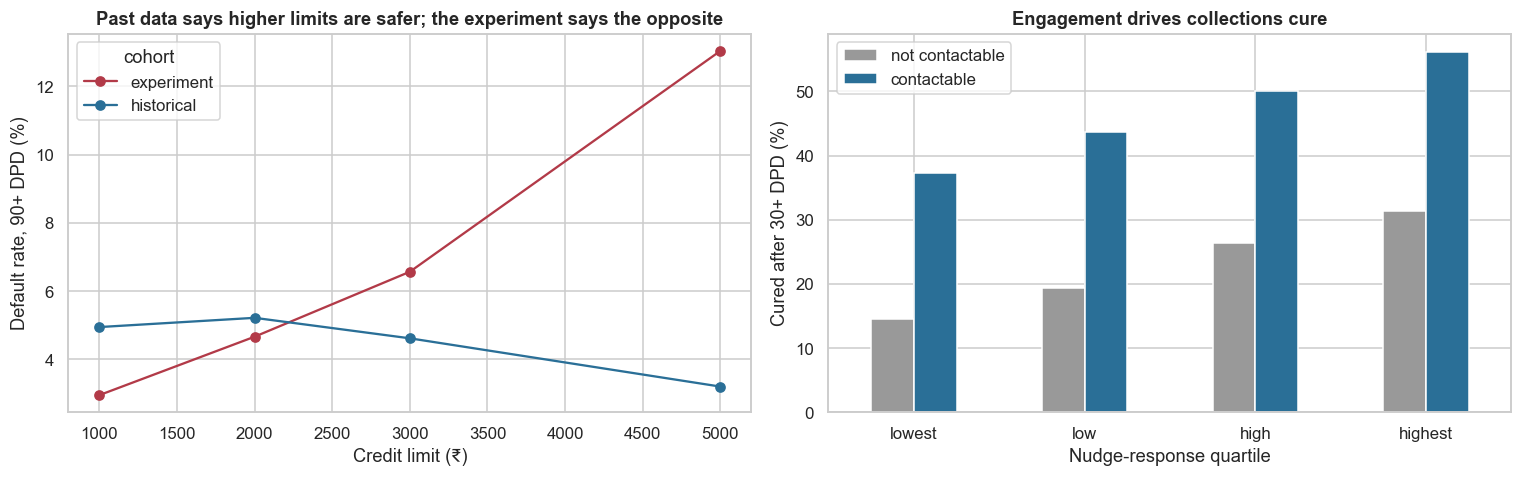

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
g = df.groupby(["cohort", "credit_limit"]).default_90dpd.mean().unstack(0) * 100
g.plot(marker="o", ax=axes[0], color=["#b23a48", "#2a6f97"]); axes[0].set_xlabel("Credit limit (₹)"); axes[0].set_ylabel("Default rate, 90+ DPD (%)")
axes[0].set_title("Past data says higher limits are safer; the experiment says the opposite"); axes[0].legend(title="cohort")
dq = df[df.cured_after_dpd30 >= 0].copy(); dq["response band"] = pd.qcut(dq.nudge_response_rate, 4, labels=["lowest", "low", "high", "highest"])
cr = dq.groupby(["response band", "contactable"]).cured_after_dpd30.mean().unstack() * 100; cr.columns = ["not contactable", "contactable"]
cr.plot(kind="bar", ax=axes[1], color=["#999", "#2a6f97"]); axes[1].set_xlabel("Nudge-response quartile"); axes[1].set_ylabel("Cured after 30+ DPD (%)")
axes[1].set_title("Engagement drives collections cure"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Takeaway:** - **Left, the key chart of this notebook:** in the **historical** cohort, default *falls* as the limit rises (4.9% at ₹1k → 3.2% at ₹5k). In the **randomised experiment** it *rises* steeply (3.0% → 13.0%). The two cohorts are similar customers; only the way limits were assigned differs. The historical pattern is **confounding**: the old rule gave higher limits to better customers.
- **Right:** among customers who fall 30+ days behind, the chance of being cured by collections roughly **doubles when the customer is contactable**, and rises further with responsiveness to nudges (from ≈ 15% to ≈ 60% across groups).

## 7. Statistical Analysis (core section)

### 7.1 Which behaviours separate defaulters? (screening)

**(a) Why?** Before modelling, check each feature's univariate separation with a test that does not assume normality (wallet features are skewed): **Mann–Whitney U** with the **rank-biserial correlation** as the effect size (± 0.1 small, 0.3 medium, 0.5 large), Holm across 16 features. Computed on the historical cohort, where the score is built.

In [7]:
FEAT = ["tenure_months", "txn_count_6m", "wallet_spend_6m", "bill_pay_share", "ontime_bill_rate", "topup_regularity", "low_balance_days_6m", "p2p_out_share",
        "gaming_share", "device_changes_6m", "city_changes_6m", "app_sessions_per_week", "contactable", "nudge_response_rate", "sessions_missing"]
h = df[H]; rows = []
for f in FEAT:
    a, b = h.loc[h.default_90dpd == 1, f], h.loc[h.default_90dpd == 0, f]
    u = stats.mannwhitneyu(a, b); r = 2 * u.statistic / (len(a) * len(b)) - 1
    rows.append((f, a.median(), b.median(), r, u.pvalue))
scr = pd.DataFrame(rows, columns=["feature", "median defaulters", "median non-defaulters", "rank-biserial r", "p"]).set_index("feature")
scr["p_holm"] = multipletests(scr.p, method="holm")[1]; scr.sort_values("rank-biserial r", key=abs, ascending=False).round(4)

,median defaulters,median non-defaulters,rank-biserial r,p,p_holm
feature,,,,,
low_balance_days_6m,6.0000,5.0000,0.2740,0.0000,0.0000
topup_regularity,0.4520,0.5090,-0.1425,0.0000,0.0000
bill_pay_share,0.2340,0.2730,-0.1411,0.0000,0.0000
p2p_out_share,0.2595,0.2300,0.1225,0.0000,0.0000
ontime_bill_rate,0.7970,0.8220,-0.1065,0.0000,0.0000
nudge_response_rate,0.3580,0.3910,-0.0856,0.0000,0.0000
wallet_spend_6m,"11,300.0000","10,440.0000",0.0699,0.0000,0.0000
gaming_share,0.0550,0.0500,0.0574,0.0000,0.0000
app_sessions_per_week,5.4000,5.0000,0.0500,0.0000,0.0000


**(c)/(f) Observation:** the features most associated with default (Holm p < 0.0001) are:
- **Low-balance days**, with the largest effect (rank-biserial r = +0.27, small to medium).
- **Irregular top-ups** (−0.14).
- **A lower share of bills paid via the wallet** (−0.14).
- **More P2P transfers out** (+0.12).
- **Lower on-time bill payment** (−0.11).

Engagement features are weak for default (nudge response −0.09; contactable −0.03). Tenure, transaction count and the session-missing flag carry no signal. **(f) Business meaning:** "payment patterns" and "outstanding amounts" (the documented families) do the work for the default score. No single feature is strong, which is why a combined score is needed.

### 7.2 Building the score (MobiScore-style) and testing it out of cohort

We train on the **historical** cohort and test on the **experiment** cohort, a different set of users whose limits are random, so their default risk does not depend on the old rule's choices. Two models: **logistic regression** (log-scaled, standardised features; the transparent "scorecard") and **gradient boosting**. Credit limit is deliberately **excluded**: the score must describe the customer, not the decision we are about to make. We report AUC with a DeLong-style bootstrap CI, KS, and decile rank ordering.

In [8]:
def X_(d):
    X = d[FEAT].copy()
    for c in ["txn_count_6m", "wallet_spend_6m", "low_balance_days_6m", "app_sessions_per_week", "tenure_months"]: X[c] = np.log1p(X[c])
    return X
lg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(X_(df[H]), df.default_90dpd[H])
hg = HGB(max_iter=300, learning_rate=0.06, random_state=SEED).fit(df.loc[H, FEAT], df.default_90dpd[H])
ye = df.default_90dpd.values[E]; p_lg = lg.predict_proba(X_(df[E]))[:, 1]; p_hg = hg.predict_proba(df.loc[E, FEAT])[:, 1]
def ks(y, p): o = np.argsort(-p); yy = y[o]; return np.max(np.abs(np.cumsum(yy) / yy.sum() - np.cumsum(1 - yy) / (1 - yy).sum()))
res = []
for nm, p in (("logistic scorecard", p_lg), ("gradient boosting", p_hg)):
    bs = [roc_auc_score(ye[i], p[i]) for i in (RNG.integers(0, len(ye), len(ye)) for _ in range(300))]
    res.append((nm, roc_auc_score(ye, p), np.percentile(bs, 2.5), np.percentile(bs, 97.5), ks(ye, p), roc_auc_score(df._q.values[E] < np.quantile(df._q.values[E], 0.2), p)))
print(pd.DataFrame(res, columns=["model", "AUC (experiment cohort)", "CI low", "CI high", "KS", "AUC for spotting the true bottom-20% quality"]).set_index("model").round(4).to_string())
df["score"] = np.nan; df.loc[E, "score"] = p_lg; df.loc[H, "score"] = lg.predict_proba(X_(df[H]))[:, 1]
df["band"] = pd.qcut(df.score.rank(method="first"), 5, labels=["A (safest)", "B", "C", "D", "E (riskiest)"])
dec = df[E].groupby("band").agg(users=("user_id", "size"), default_rate=("default_90dpd", "mean"), mean_score=("score", "mean"))
dec

                    AUC (experiment cohort)  CI low  CI high     KS  AUC for spotting the true bottom-20% quality
model                                                                                                            
logistic scorecard                   0.7141  0.7067   0.7220 0.3188                                        0.8403
gradient boosting                    0.7015  0.6937   0.7091 0.2942                                        0.8134


,users,default_rate,mean_score
band,,,
A (safest),13204,0.0203,0.0178
B,13134,0.0329,0.0296
C,13239,0.0529,0.0402
D,13183,0.0779,0.0539
E (riskiest),13218,0.1560,0.0873


**Observation:** - **Out-of-cohort performance:** trained on the historical cohort and tested on the experiment cohort, the **logistic scorecard reaches AUC 0.714** (CI 0.707–0.722, KS 0.32). It is slightly **better than gradient boosting** (0.702): with smooth, mostly monotone effects, the simpler model wins.
- **It finds the truly weak customers:** AUC 0.84 for identifying the hidden bottom 20% of quality.
- **Rank ordering is clean:** default rises monotonically across score fifths, **2.0% → 3.3% → 5.3% → 7.8% → 15.6%** (a 7.7× top/bottom ratio).

**(f) Business meaning:** the score is good enough to drive pre-approval and limit bands, and the explainable logistic version can be used.

### 7.3 Engagement features: for default, or for collections?

The documented features "**contactability**" and "**responsiveness**" are unusual in a credit score. We test them twice, with likelihood-ratio tests and odds ratios with 95% CIs:
- **Default model:** do they add to the behaviour features in predicting default?
- **Cure model:** among users who reach 30+ DPD (not yet defaulted), do they predict being **cured** by collections?

In [9]:
d = df.copy(); d["l_spend"] = np.log1p(d.wallet_spend_6m); d["l_lowbal"] = np.log1p(d.low_balance_days_6m)
base = "ontime_bill_rate + topup_regularity + l_lowbal + device_changes_6m + gaming_share + l_spend"
m0 = smf.logit(f"default_90dpd ~ {base}", data=d[H]).fit(disp=0); m1 = smf.logit(f"default_90dpd ~ {base} + contactable + nudge_response_rate", data=d[H]).fit(disp=0)
cu = d[(d.cured_after_dpd30 >= 0)]
c0 = smf.logit(f"cured_after_dpd30 ~ {base}", data=cu).fit(disp=0); c1 = smf.logit(f"cured_after_dpd30 ~ {base} + contactable + nudge_response_rate", data=cu).fit(disp=0)
out = []
for nm, a, b in (("default (historical cohort)", m0, m1), ("cure after 30+ DPD (all users)", c0, c1)):
    LR = 2 * (b.llf - a.llf); ci = np.exp(b.conf_int())
    out.append((nm, int(b.nobs), LR, stats.chi2.sf(LR, 2), np.exp(b.params["contactable"]), ci.loc["contactable", 0], ci.loc["contactable", 1],
                np.exp(b.params["nudge_response_rate"] * 0.1), np.exp(ci.loc["nudge_response_rate", 0] * 0.1), np.exp(ci.loc["nudge_response_rate", 1] * 0.1)))
eng = pd.DataFrame(out, columns=["outcome", "n", "LR χ² (2 df)", "p", "OR contactable", "CI low", "CI high", "OR per +10 pp nudge response", "CI low ", "CI high "]).set_index("outcome")
print(f"Cure rate among 30+ DPD users: contactable {cu[cu.contactable == 1].cured_after_dpd30.mean():.1%} vs not {cu[cu.contactable == 0].cured_after_dpd30.mean():.1%}")
eng.round(4)

Cure rate among 30+ DPD users: contactable 46.9% vs not 22.6%


,n,LR χ² (2 df),p,OR contactable,CI low,CI high,OR per +10 pp nudge response,CI low,CI high
outcome,,,,,,,,,
default (historical cohort),66268,27.8594,0.0000,0.8818,0.8045,0.9666,0.9588,1.0562,1.0820
cure after 30+ DPD (all users),23711,"1,393.3028",0.0000,2.9902,2.7736,3.2236,1.1589,1.4657,1.6478


**(c)/(f) Observation:** **the documented engagement features matter for collections, not for approval.**
- **For default,** adding contactability and responsiveness is statistically significant (LR χ² = 28) but practically small: being contactable lowers the odds of default by ~12% (OR 0.88, CI 0.80–0.97), and responsiveness has no clear effect (OR 0.96 per +10 pp, CI includes 1).
- **For cure after 30+ DPD,** the effect is large (LR χ² = 1,393): contactable customers have **3.0× the odds of cure** (CI 2.8–3.2), and each +10 pp of nudge response multiplies the odds by 1.53.
- **Raw cure rates:** 46.9% vs 22.6%.

**(f) Business meaning:** this confirms the documented interpretation, that good feature design anticipates the downstream process. Feed these features to a **collections/cure model** that decides how early and how to contact each delinquent customer.

### 7.4 Why a randomised test? The confounding trap in historical limits

**(a)** In the historical cohort, limits were set by the old rule, which partly saw customer quality. A regression of default on limit therefore mixes two things: the effect *of the limit* and the fact that *good customers got bigger limits*. We estimate the limit effect three ways:
1. **Historical, naive:** default ~ limit.
2. **Historical, adjusted** for the behaviour score.
3. **Experiment:** default ~ limit, where the limit was randomly assigned, so it is unbiased.

In [10]:
d["lim_k"] = d.credit_limit / 1000; d["logit_score"] = np.log(d.score / (1 - d.score))
fits = {"1 historical, naive": smf.logit("default_90dpd ~ lim_k", data=d[H]).fit(disp=0),
        "2 historical, adjusted for score": smf.logit("default_90dpd ~ lim_k + logit_score", data=d[H]).fit(disp=0),
        "3 experiment (randomised)": smf.logit("default_90dpd ~ lim_k", data=d[E]).fit(disp=0),
        "3b experiment, adjusted for score": smf.logit("default_90dpd ~ lim_k + logit_score", data=d[E]).fit(disp=0)}
conf = pd.DataFrame({k: {"OR per +₹1,000 limit": np.exp(f.params["lim_k"]), "CI low": np.exp(f.conf_int().loc["lim_k", 0]), "CI high": np.exp(f.conf_int().loc["lim_k", 1]),
                         "p": f.pvalues["lim_k"]} for k, f in fits.items()}).T
print(f"Correlation of limit with hidden true quality: historical {np.corrcoef(d.lim_k[H], d._q[H])[0, 1]:.2f} vs experiment {np.corrcoef(d.lim_k[E], d._q[E])[0, 1]:.3f}")
conf.round(4)

Correlation of limit with hidden true quality: historical 0.63 vs experiment -0.011


,"OR per +₹1,000 limit",CI low,CI high,p
"1 historical, naive",0.8908,0.8663,0.9159,0.0000
"2 historical, adjusted for score",1.0339,1.0040,1.0647,0.0261
3 experiment (randomised),1.4733,1.4435,1.5038,0.0000
"3b experiment, adjusted for score",1.4936,1.4625,1.5254,0.0000


**Observation:** - **Historical data, naive:** each +₹1,000 of limit appears to **lower** default odds by 11% (OR 0.89, CI 0.87–0.92). This is a wrong answer that would encourage handing out bigger limits.
- **Adjusting for the score** only partly fixes it (OR 1.03): the old rule used information the score does not fully capture. In the historical cohort, limit correlates **0.63** with hidden true quality.
- **The randomised experiment** (correlation −0.01) gives the causal answer: **+₹1,000 of limit raises default odds by 47%** (OR 1.47, CI 1.44–1.50). Adjusting for the score barely changes it (1.49), as randomisation guarantees.

**Business meaning:** never estimate limit effects from historical limits. **Only a randomised limit test answers the limit question**, a standard practice at card issuers that this case strongly supports.

### 7.5 Checking the experiment, then measuring the limit effect by score band

**Randomisation checks:**
- **SRM:** χ² test that the four arms got equal numbers.
- **Balance:** standardised mean difference (SMD) of key features across arms; |SMD| < 0.1 means balanced.

**Effects:** default rate, spend, revenue, loss and profit by limit × score band. The heterogeneity test is the **LR test of limit × band interactions** in a logistic default model. A trend test (Cochran–Armitage via logistic slope) runs within each band.

SRM: arm sizes {1000: 16530, 2000: 16424, 3000: 16551, 5000: 16473}, χ² p = 0.897 | max |SMD| across arms: ontime_bill_rate 0.030, topup_regularity 0.011, wallet_spend_6m 0.007, score 0.029


Limit × band heterogeneity in default: LR χ² = 88.4, df = 4, p = 2.9e-18


,"OR default per +₹1,000",p,p_holm
band,,,
A (safest),1.1559,0.0004,0.0004
B,1.3484,0.0000,0.0000
C,1.3758,0.0000,0.0000
D,1.5177,0.0000,0.0000
E (riskiest),1.6319,0.0000,0.0000


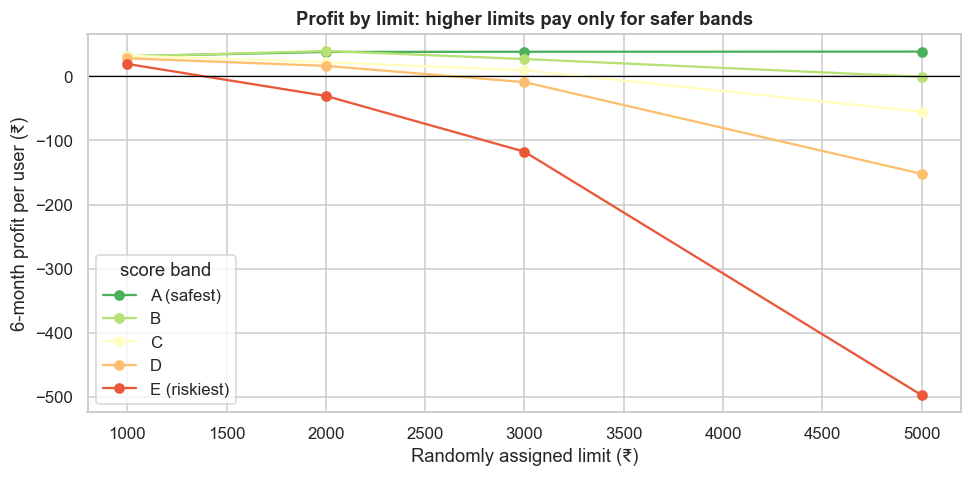

users  default      spend  revenue     loss    profit
band         credit_limit                                                       
A (safest)   1000           3351   0.0150 1,546.3440  41.9620  10.9590   31.0040
             2000           3243   0.0180 2,411.5700  60.3310  22.6390   37.6920
             3000           3394   0.0220 2,810.0380  70.6340  32.6560   37.9780
             5000           3216   0.0260 3,148.6230  82.1780  43.9700   38.2080
B            1000           3292   0.0180 1,561.4370  44.6680  14.1090   30.5590
             2000           3346   0.0220 2,522.2590  65.7640  26.5820   39.1830
             3000           3225   0.0350 3,057.2250  80.2840  53.6280   26.6560
             5000           3271   0.0560 3,517.6310 101.6150 102.6230   -1.0090
C            1000           3340   0.0250 1,580.1020  50.7650  18.9260   31.8390
             2000           3335   0.0420 2,651.6910  77.7650  55.9930   21.7720
             3000           3293   0.0530 3,240.3280  95.3240  86.1880    9.1360
             5000           3271   0.0920 3,731.9810 122.3330 177.9140  -55.5810
D            1000           3297   0.0330 1,603.6700  53.8420  26.0360   27.8060
             2000           3203   0.0510 2,705.6350  85.1800  69.2260   15.9540
             3000           3341   0.0700 3,356.2680 108.7270 118.1030   -9.3760
             5000           3342   0.1550 3,992.3970 152.0290 304.2650 -152.2360
E (riskiest) 1000           3250   0.0580 1,631.6090  65.0930  46.0840   19.0080
             2000           3297   0.1000 2,848.7990 111.1190 141.9400  -30.8210
             3000           3298   0.1470 3,608.4480 144.1100 261.8130 -117.7030
             5000           3373   0.3140 4,377.7380 207.6220 704.6550 -497.0340

In [11]:
ex = d[E].copy()
cnt = ex.credit_limit.value_counts().sort_index(); srm = stats.chisquare(cnt.values)
smd = {}
for f in ["ontime_bill_rate", "topup_regularity", "wallet_spend_6m", "score"]:
    m_ = ex.groupby("credit_limit")[f].mean(); s_ = ex[f].std(); smd[f] = (m_.max() - m_.min()) / s_
print(f"SRM: arm sizes {cnt.to_dict()}, χ² p = {srm.pvalue:.3f} | max |SMD| across arms: " + ", ".join(f"{k} {v:.3f}" for k, v in smd.items()))
mA = smf.logit("default_90dpd ~ C(band) + lim_k", data=ex).fit(disp=0); mB = smf.logit("default_90dpd ~ C(band) * lim_k", data=ex).fit(disp=0)
LR = 2 * (mB.llf - mA.llf); print(f"Limit × band heterogeneity in default: LR χ² = {LR:.1f}, df = 4, p = {stats.chi2.sf(LR, 4):.2g}")
slopes = []
for b in ex.band.cat.categories:
    s_ = smf.logit("default_90dpd ~ lim_k", data=ex[ex.band == b]).fit(disp=0); slopes.append((b, np.exp(s_.params["lim_k"]), s_.pvalues["lim_k"]))
sl = pd.DataFrame(slopes, columns=["band", "OR default per +₹1,000", "p"]).set_index("band"); sl["p_holm"] = multipletests(sl.p, method="holm")[1]
eff = ex.groupby(["band", "credit_limit"]).agg(users=("user_id", "size"), default=("default_90dpd", "mean"), spend=("line_spend_6m", "mean"), revenue=("revenue_inr", "mean"),
                                               loss=("loss_inr", "mean"), profit=("profit", "mean"))
display(sl.round(4))
fig, ax = plt.subplots(figsize=(9, 4.5))
for b, c_ in zip(ex.band.cat.categories, sns.color_palette("RdYlGn_r", 5)):
    e_ = eff.loc[b]; ax.plot(e_.index, e_.profit, "o-", color=c_, label=b)
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("Randomly assigned limit (₹)"); ax.set_ylabel("6-month profit per user (₹)"); ax.set_title("Profit by limit: higher limits pay only for safer bands"); ax.legend(title="score band")
plt.tight_layout(); plt.show()
eff.round(3)

**Takeaway:** - **Randomisation worked:** arm sizes are equal (SRM χ² p = 0.90), and all features are balanced across arms (max |SMD| = 0.03).
- **The limit effect differs by band** (LR χ² = 88, p ≈ 3e-18). Each +₹1,000 raises default odds by **16% in the safest band and 63% in the riskiest** (all Holm p < 0.001).
- **Profit per user (chart):**
  - **Safest band (A):** profit is flat-to-rising with limit (₹31 at ₹1k → ₹38 at ₹5k). Extra spend roughly pays for the extra risk.
  - **Bands C–E:** higher limits destroy profit. In the riskiest band, ₹5k earns ₹208 of revenue but loses ₹705 to defaults (−₹497 per user).
- **Business meaning:** a higher limit is a *risk decision*, not just a growth lever. It pays only for the safest customers.

### 7.6 Choosing limits per band, evaluated honestly

We split the experiment cohort randomly in two halves:
- **Design half:** pick, for each score band, the limit with the highest mean profit (or "do not offer" if every limit loses money).
- **Evaluation half:** estimate the profit of that policy and of the alternatives on users whose random limit equals the policy's limit, weighted ×4 because each limit had a 1/4 chance. This is an inverse-propensity estimate, unbiased because assignment was random.

Paired bootstrap CIs for the differences, plus the policy's default rate (guardrail ≤ 6%).

In [12]:
half = RNG.random(len(ex)) < 0.5; des, ev = ex[half], ex[~half]
LIM = [1000, 2000, 3000, 5000]; bands = list(ex.band.cat.categories)
pm = des.groupby(["band", "credit_limit"]).profit.mean().unstack()
policy = {b: (int(pm.loc[b].idxmax()) if pm.loc[b].max() > 0 else 0) for b in bands}
old_rule_like = {b: l for b, l in zip(bands, [5000, 3000, 2000, 2000, 1000])}
POL = {"uniform ₹1,000": {b: 1000 for b in bands}, "uniform ₹2,000": {b: 2000 for b in bands}, "uniform ₹3,000": {b: 3000 for b in bands},
       "uniform ₹5,000": {b: 5000 for b in bands}, "score-tiered (old-rule style)": old_rule_like, "profit-optimal per band (design half)": policy}
def value(d_, pol):
    lim = d_.band.map(pol).astype(float).values; match = d_.credit_limit.values == lim; off = lim == 0
    prof = np.where(off, 0.0, match * d_.profit.values * 4); dflt = np.where(off, 0.0, match * d_.default_90dpd.values * 4); offered = np.where(off, 0.0, match * 4.0)
    return prof, dflt, offered
rows, PV = [], {}
for nm, pol in POL.items():
    prof, dflt, offd = value(ev, pol); PV[nm] = prof
    rows.append((nm, ", ".join(f"{b.split()[0]}:{'—' if pol[b] == 0 else pol[b] // 1000}k" for b in bands), prof.mean(), dflt.sum() / max(offd.sum(), 1), offd.mean()))
pt = pd.DataFrame(rows, columns=["policy", "limits A–E", "profit per user ₹ (evaluation half)", "default rate of offered", "share offered"]).set_index("policy")
best_uni = pt.loc[[i for i in pt.index if i.startswith("uniform")], "profit per user ₹ (evaluation half)"].idxmax()
dlt = PV["profit-optimal per band (design half)"] - PV[best_uni]
bs = [dlt[RNG.integers(0, len(dlt), len(dlt))].mean() for _ in range(2000)]
print(f"Profit-optimal vs best uniform ({best_uni}): {dlt.mean():+.1f} ₹/user (95% bootstrap CI {np.percentile(bs, 2.5):+.1f} to {np.percentile(bs, 97.5):+.1f})")
pt.round(3)

Profit-optimal vs best uniform (uniform ₹1,000): +2.5 ₹/user (95% bootstrap CI -1.4 to +6.1)


,limits A–E,profit per user ₹ (evaluation half),default rate of offered,share offered
policy,,,,
"uniform ₹1,000","A:1k, B:1k, C:1k, D:1k, E:1k",27.6180,0.0310,1.0140
"uniform ₹2,000","A:2k, B:2k, C:2k, D:2k, E:2k",16.7650,0.0460,0.9920
"uniform ₹3,000","A:3k, B:3k, C:3k, D:3k, E:3k",-12.5220,0.0670,0.9970
"uniform ₹5,000","A:5k, B:5k, C:5k, D:5k, E:5k",-144.7550,0.1330,0.9970
score-tiered (old-rule style),"A:5k, B:3k, C:2k, D:2k, E:1k",23.1900,0.0430,0.9870
profit-optimal per band (design half),"A:5k, B:2k, C:1k, D:1k, E:1k",30.1420,0.0340,1.0080


**Observation:** the policy chosen on the design half, **A:₹5k, B:₹2k, C–E:₹1k**, earns **₹30.1 per user** on the evaluation half (default rate 3.4%):
- **Uniform ₹1,000:** ₹27.6 (3.1% default). This is the best uniform policy.
- **Uniform ₹2,000:** ₹16.8.
- **Old-rule-style tiers (₹5k → ₹1k):** ₹23.2. They give risky bands too much.
- **Uniform ₹3,000 or ₹5,000:** loses money (−₹12.5 and −₹144.8).

The gain of the optimal policy over uniform ₹1k is **+₹2.5 per user, CI −₹1.4 to +₹6.1**, so **we cannot reject H0**: the evidence favours it but is not yet conclusive. All sensible policies pass the 6% default guardrail; uniform ₹5k does not (13.3%). **Business meaning:** the big, certain win is *not* giving large limits to risky users. Fine-tuning limits for safe users is a small, still-uncertain gain that needs a bigger test.

### 7.7 Power: how big must a limit test be?

Profit per user is very noisy (most users earn ₹30–150; a few defaulters lose up to ₹4,000). We compute the users needed **per arm per band** to detect a ₹20 per-user profit difference (80% power, α = 0.05), from the observed standard deviation of profit in each band.

In [13]:
pw = ex.groupby("band").profit.std().to_frame("profit SD ₹")
for delta in (10, 20, 40):
    pw[f"n per arm for Δ = ₹{delta}"] = np.ceil(2 * (1.96 + 0.84) ** 2 * pw["profit SD ₹"] ** 2 / delta ** 2).astype(int)
pw["n per arm in this test"] = ex.groupby(["band", "credit_limit"]).size().groupby(level=0).min()
pw.round(1)

,profit SD ₹,n per arm for Δ = ₹10,n per arm for Δ = ₹20,n per arm for Δ = ₹40,n per arm in this test
band,,,,,
A (safest),209.2000,6864,1716,429,3216
B,297.6000,13886,3472,868,3225
C,391.6000,24045,6012,1503,3271
D,492.7000,38061,9516,2379,3203
E (riskiest),748.7000,87893,21974,5494,3250


**Observation:** profit is very noisy: its standard deviation is ₹209 per user in the safest band and **₹749 in the riskiest**, because a few defaults lose up to ₹4,000. Detecting a **₹20** profit difference between two limits needs ≈ **1,700 users per arm in band A** but **≈ 22,000 in band E**. To detect ₹10 differences, about 4× more. This test (≈ 3,200 per arm per band) is powered for ₹20 differences only in bands A–B. **Business meaning:** that is why the profit-optimal policy's +₹2.5 gain is not yet significant. A permanent random-limit holdout of a few percent of new users, run for several cycles, provides the needed sample cheaply.

## 8. ML Section — brief

- **Logistic vs gradient boosting:** compared in 7.2 without tuning. The logistic scorecard is the production choice if its AUC is within ~0.01 of boosting: it is explainable to customers (RBI's Digital Lending Guidelines expect reasons for credit decisions) and stable.
- **Limit is never a model input.** The score describes the customer. The limit is a decision evaluated by the experiment (7.4–7.6).
- **Two-model design:** the documented engagement features go mainly into a **collections/cure model**, which decides whom to call and how early, not into the approval score.

## 9. Business Translation — ₹ impact

In [14]:
N_USERS = 1e6                                                            # scale: 10 lakh pre-approved users per 6-month cycle (assumption, D-15-07)
imp = pt[["profit per user ₹ (evaluation half)", "default rate of offered", "share offered"]].copy()
imp["₹ crore per 6 months (10 lakh users)"] = imp["profit per user ₹ (evaluation half)"] * N_USERS / 1e7
imp["vs best uniform (₹ crore)"] = imp["₹ crore per 6 months (10 lakh users)"] - imp.loc[best_uni, "₹ crore per 6 months (10 lakh users)"]
cure_gain = (cu[cu.contactable == 1].cured_after_dpd30.mean() - cu[cu.contactable == 0].cured_after_dpd30.mean())
avg_bal_30 = df.loc[(df.dpd30_6m == 1) & (df.default_90dpd == 0), "max_utilised"].mean()
print(f"Collections: contactable users cure {cure_gain:.1%} more often; average balance at 30+ DPD ≈ ₹{avg_bal_30:,.0f}")
imp.round(3)

Collections: contactable users cure 24.3% more often; average balance at 30+ DPD ≈ ₹1,791


,profit per user ₹ (evaluation half),default rate of offered,share offered,₹ crore per 6 months (10 lakh users),vs best uniform (₹ crore)
policy,,,,,
"uniform ₹1,000",27.6180,0.0310,1.0140,2.7620,0.0000
"uniform ₹2,000",16.7650,0.0460,0.9920,1.6760,-1.0850
"uniform ₹3,000",-12.5220,0.0670,0.9970,-1.2520,-4.0140
"uniform ₹5,000",-144.7550,0.1330,0.9970,-14.4760,-17.2370
score-tiered (old-rule style),23.1900,0.0430,0.9870,2.3190,-0.4430
profit-optimal per band (design half),30.1420,0.0340,1.0080,3.0140,0.2520


**Takeaway (business reading):** per **10 lakh pre-approved users per 6 months**:
- **Profit by policy:**
  - Profit-optimal limits: ≈ **₹3.0 crore**.
  - Uniform ₹1k: ≈ ₹2.8 crore.
  - Old-rule-style tiers: ≈ ₹2.3 crore (≈ ₹0.7 crore less than optimal).
  - Uniform ₹2k: ₹1.7 crore.
  - Uniform ₹5k: **a loss of ≈ ₹14.5 crore**.
- **Reading:** the score's main value is **protection against over-limiting risky users** (≈ ₹17 crore between the best and worst limit strategies). Optimising limits for safe users adds only ≈ ₹0.25 crore and is not yet statistically confirmed.
- **Collections:** contactable delinquent customers cure 24 pp more often. With ≈ ₹1,800 average balance at 30+ DPD, every 1 lakh delinquent accounts made contactable is worth roughly **₹4 crore of balances cured** (an illustrative upper bound).
- Margins here are thin (2% merchant fee). Real BNPL economics include interest and convenience fees, which raise profits at every limit.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** the score ranks risk (AUC 0.71, monotone bands).
- **H2:** engagement adds little to default (small OR) ✅ but strongly to cure ✅.
- **H3 ✅:** limit raises default causally (+47% odds per ₹1k), more for risky bands.
- **H4 ❌ (not significant):** the profit-optimal policy beats uniform ₹1k by +₹2.5 per user (CI includes 0).
- **Guardrail:** passed by every policy except uniform ₹5k.

**I recommend:**
1. **Pre-approve on the behaviour score** (logistic scorecard: explainable, as strong as boosting here).
2. **Start limits low and earn upward:** ₹1k for bands C–E, ₹2k for band B, ₹5k only for band A. Raise limits after on-time repayment cycles.
3. **Never infer limit effects from historical limits.** Keep a **permanent 2–5% random-limit holdout** and review the band-by-limit profit table every cycle, powered to detect ₹20 differences.
4. **Collections model:** use contactability and responsiveness to prioritise and time collection contacts. Fix unreachable numbers at onboarding (verified phone), since that directly lifts cure rates.
5. **Compliance:** document the limit policy under the lender's credit policy (RBI DLG), with the KFS showing the limit and charges.

**KPIs:** 6-month profit per pre-approved user by band; default rate per band and limit; cure rate after 30+ DPD by contactability; limit-increase uptake and post-increase default; holdout sample size per arm.

## 11. Risks, Limitations and Next Steps

- **Synthetic effects:** the size and shape of the limit effect were assumed. A real randomised test is essential (7.7 gives the sample size).
- **Ethics of limit experiments:** randomising limits is acceptable when every arm is within credit policy (here ₹1k–5k for pre-approved users). Do not randomise users into limits the policy would reject, and disclose limits clearly (RBI DLG Key Fact Statement).
- **Six months is short:** profit from higher limits accrues over the customer's life (repeat use, cross-sell). Losses also arrive late. Track 12-month outcomes before scaling.
- **Feedback loops:** once limits follow the score, future historical data are confounded again. Keep a small **permanent random-limit holdout** (e.g., 2–5%) for ongoing learning.
- **Behavioural data and consent:** wallet behaviour, device and location data need explicit consent and purpose limitation under the DPDP Act. Engagement data used for collections must respect RBI's fair-practices code (no harassment, contact-hour limits).

## 12. Appendix

| Quantity | Formula |
|---|---|
| Rank-biserial | r = 2U/(n₁n₂) − 1 |
| Profit per user | revenue (2% × line spend + collected late fees) − loss (85% × utilised on default) |
| IPW policy value | V̂(π) = mean( 1{assigned limit = π(x)} · profit / (1/4) ) |
| SMD | (max arm mean − min arm mean) / pooled SD |
| Sample size per arm | n = 2(z₀.₉₇₅ + z₀.₈)² σ² / Δ² |
| Confounding | E[default ∣ limit] ≠ effect of limit when limit depends on quality |

| Term | Meaning |
|---|---|
| BNPL / credit line | Buy now, pay later; a small revolving limit |
| Behaviour score | A risk score built from on-platform behaviour, not the bureau |
| Pre-approval | Offering credit before the customer applies |
| Randomised limit test | Assigning limits at random within policy to learn their effect |
| Confounding | A hidden common cause (quality) that makes two things look related |
| Cure | A delinquent customer brought back to current |
| DPD | Days past due |